📌 Данная практическая работа посвящена предобработки исходных данных. В рамкках практической работы студенту предстоит:

*   Поиск, удаление пропусков → минимизировать ошибки при расчётах;
*   Преобразовать SMILES комплексов → корректно сравнить молекулы;
*   Канонизировать SMILES, удалить дупликатов → минимизировать искажение статистики;
*   Найти PAINS → убрать ложноположительные структуры;
*   Провести анализ биологической активности (ADME) → убрать соединения с низкой биолоической активностью;

✅ Исходные данные:
*   Набор соединений "practise_2_test.csv" (https://github.com/OlgaOVolkova/Biochemistry_26-27_Practice/blob/main/data/practice_2_test.csv)
*   Набор PAINS "pains.smart" (https://github.com/OlgaOVolkova/Biochemistry_26-27_Practice/blob/main/data/pains.smarts)




In [ ]:
# Установка библиотек:
! pip install rdkit mols2grid --quiet

# Установка модулей

import pandas as pd # работа с датафреймами

from rdkit.Chem import PandasTools # pandas "для работы с молекулами в датафрейме"
from rdkit import Chem # основной модуль для базовых функций (чтение SMILES, создание mol, расчет дескрипторов и т.д.)
import mols2grid # модуль для визуализации

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.1/38.1 MB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.5/83.5 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 30.7 MB/s eta 0:00:00


In [ ]:
# Загрузка датасета "practice_3.csv"
#df = pd.read_csv('practice_2_test.csv')
df = pd.read_csv("https://raw.githubusercontent.com/OlgaOVolkova/Biochemistry_26-27_Practice/main/data/practice_2_test.csv")
print('Кол-во строк: ', len(df))
df.head(5)

Кол-во строк:  9129


,molecule_chembl_id,SMILES,IC50_nM
0,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,41.0
1,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,300.0
2,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,7820.0
3,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,170.0
4,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,40.0


📌 Какие данные есть в датафрейме:
*   **compound_ID** - идентификатор соединения
*   **SMILES** - представление структуры соединения в виде SMILES
*   **IC50_nM** - Значения параметра аффинности IC50 в нМ

# ⚡ 1. Поиск, удаление пропусков

In [ ]:
# Краткая информация по датасету df
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9129 entries, 0 to 9128
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   molecule_chembl_id  9128 non-null   object 
 1   SMILES              9113 non-null   object 
 2   IC50_nM             8979 non-null   float64
dtypes: float64(1), object(2)
memory usage: 214.1+ KB


In [ ]:
rows_with_nan = df[df.isna().any(axis=1)] # df.isna() - создаем таблицу (True/False, где True - пропуск), (axis=1) - проверка по строкам
print('Кол-во строк с пропусками: ', len(rows_with_nan)) # расчет кол-ва строк
rows_with_nan

Кол-во строк с пропусками:  164


,molecule_chembl_id,SMILES,IC50_nM
32,CHEMBL42423,O=[N+]([O-])c1ccc(O)c(O)c1,NaN
39,CHEMBL441343,O=C(O)c1ccc(O)cc1,NaN
49,CHEMBL67057,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,NaN
57,CHEMBL69129,Nc1ncnc2c1c(-c1ccc(Oc3ccccc3)cc1)cn2C1CCC(O)C1,NaN
84,CHEMBL77436,CN(C)c1ccc(/C=C(\C#N)C(=O)O)cc1,NaN
...,...,...,...
5166,CHEMBL1200528,NaN,2955.0
5169,CHEMBL11359,NaN,2621.0
5170,CHEMBL6067481,NaN,1500.0
5180,CHEMBL1909064,NaN,188.0


In [ ]:
# Удаление пропусков
df = df.dropna()
print('Кол-во строк после удаления пропусков: ', len(df))

Кол-во строк после удаления пропусков:  8965


#⚡ 2. Преобразование комплексов

In [ ]:
# Поиск сольватов/гидратов

df_solvate = df[df['SMILES'].str.contains(r'\.', na=False)] # - датафрейм с комплексами
print('Количество сольватов: ', len(df_solvate))
df_solvate.head(5)

Количество сольватов:  283


,molecule_chembl_id,SMILES,IC50_nM
193,CHEMBL545315,C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OCCCN...,7.4
194,CHEMBL545315,C=CC(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1OCCCN...,7.4
534,CHEMBL2448064,COc1cc2c(Nc3ccc(Cl)cc3F)ncnc2cc1OCC1CCNCC1.Cl,300.0
535,CHEMBL2448064,COc1cc2c(Nc3ccc(Cl)cc3F)ncnc2cc1OCC1CCNCC1.Cl,100.0
583,CHEMBL1744349,COc1cc2c(Nc3ccc(Cl)cc3F)ncnc2cc1OC/C=C/CN1CCCC...,90.0


In [ ]:
mols2grid.display(df_solvate)

In [ ]:
def clean_solvate(smiles):
  """
  Функция clean_solvate для преобразования комплексов

  Аргумент - smiles
  """
  mol = Chem.MolFromSmiles(smiles) # Преобразование стоки SMILES в объект mol
  frags = Chem.GetMolFrags(mol, asMols=True) # Определение фрагментов
  largest = max(frags, key=lambda m: m.GetNumAtoms()) # Определение наибольшего фрагмента
  return Chem.MolToSmiles(largest, isomericSmiles=True)

In [ ]:
# Применение функции clean_solvate к df_solvate
df_solvate = df[df['SMILES'].str.contains(r'\.', na=False)].copy()
df_solvate['SMILES'] = df_solvate['SMILES'].apply(clean_solvate)

In [ ]:
mols2grid.display(df_solvate)

In [ ]:
# Применение функции clean_solvate для преобразования комплексов датафрейма df
df['SMILES'] = df['SMILES'].apply(clean_solvate)
print('Кол-во строк: ', len(df))
df.head(2)

Кол-во строк:  8965


,molecule_chembl_id,SMILES,IC50_nM
0,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,41.0
1,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,300.0


#⚡ 3. Канонизация SMILES, удаление дупликатов

In [ ]:
# Сначала приводим к canonical_smiles

def get_canonical_smiles(smiles):
  """
  Функция get_canonical_smiles для SMILES приведения к canonical_smiles

  Аргумент - smiles
  """
  mol = Chem.MolFromSmiles(smiles)
  return Chem.MolToSmiles(mol, canonical=True)

In [ ]:
# Применение функции get_canonical_smiles к датафрейму df
df['SMILES'] = df['SMILES'].apply(get_canonical_smiles)

In [ ]:
# Создаём булеву маску: True для строк, которые являются дубликатами
mask = df.duplicated()

# Создаём новый датафрейм только из этих строк
df_duplicates_full = df[mask].sort_values('molecule_chembl_id')
print('Кол-во дупликатов: ', len(df_duplicates_full))
df_duplicates_full.head(11)

Кол-во дупликатов:  568


,molecule_chembl_id,SMILES,IC50_nM
3407,CHEMBL101253,Clc1ccc(Nc2nnc(Cc3ccncc3)c3ccccc23)cc1,10000.0
6743,CHEMBL1081312,Nc1ncnc2c1c(-c1cnc3[nH]ccc3c1)nn2C1CCCC1,260.0
4468,CHEMBL1088901,CN(C)CCCC(=O)Nc1ccc2ncnc(Nc3cccc(Br)c3)c2c1,1.0
4463,CHEMBL1090840,C=CC(=O)Nc1ccc2nccc(Nc3cccc(Br)c3)c2c1,1.0
6958,CHEMBL1091644,C[C@]1(O)C[C@@H](c2nc(-c3ccc4ccc(-c5ccccc5)nc4...,12500.0
4493,CHEMBL1094195,NCCc1cn(Cc2ccc(-c3cccc(C(F)(F)F)c3)cc2)c2ccc(O...,1110.0
5275,CHEMBL1095464,Cc1ccccc1Cc1cc2c(Nc3cccc(Br)c3)nc(N)nc2[nH]1,9190.0
5461,CHEMBL1095464,Cc1ccccc1Cc1cc2c(Nc3cccc(Br)c3)nc(N)nc2[nH]1,9190.0
5460,CHEMBL1095465,COc1ccc(OC)c(Cc2cc3c(Nc4cccc(Br)c4)nc(N)nc3[nH...,12620.0
4492,CHEMBL1098120,NC1CCc2c(c3cc(OCCc4ccc(O)cc4)ccc3n2CCCCCc2cccc...,1010.0


In [ ]:
# Поиск дупликатов по столбцам "molecule_chembl_id", "SMILES"
mask = df['SMILES'].duplicated(keep=False)
df_duplicates = df[mask].sort_values('molecule_chembl_id')
print('Кол-во дупликатов: ', len(df_duplicates))
df_duplicates.head(50)

Кол-во дупликатов:  4520


,molecule_chembl_id,SMILES,IC50_nM
923,CHEMBL10,C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...,96000.00
2798,CHEMBL10,C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...,33000.00
799,CHEMBL100714,COc1ccc(Nc2ncnc3cc(OC)c(OC)cc23)cc1OC,2800.00
5184,CHEMBL1009,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,2880.00
16,CHEMBL1009,N[C@@H](Cc1ccc(O)c(O)c1)C(=O)O,900000.00
3407,CHEMBL101253,Clc1ccc(Nc2nnc(Cc3ccncc3)c3ccccc23)cc1,10000.00
3388,CHEMBL101253,Clc1ccc(Nc2nnc(Cc3ccncc3)c3ccccc23)cc1,457.70
2167,CHEMBL101253,Clc1ccc(Nc2nnc(Cc3ccncc3)c3ccccc23)cc1,10000.00
1935,CHEMBL102651,C[C@@H](Nc1[nH]cnc2c3ccccc3nc1-2)c1ccccc1,419.00
5256,CHEMBL103667,Cc1ccc(-n2nc(C(C)(C)C)cc2NC(=O)Nc2ccc(OCCN3CCO...,3800.00


In [ ]:
# Удаление дупликатов по столбцам "molecule_chembl_id", "SMILES"
df = df.drop_duplicates(subset=['molecule_chembl_id'])
df = df.drop_duplicates(subset=['SMILES'])
print('Кол-во строк после удаления дупликатов: ', len(df))
df.head(2)

Кол-во строк после удаления дупликатов:  6094


,molecule_chembl_id,SMILES,IC50_nM
0,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,41.0
3,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,170.0


#⚡ 4. Поиск и удаление подструктур PAINS

<img src="https://raw.githubusercontent.com/OlgaOVolkova/Biochemistry_26-27_Practice/main/images/pains_experiment.png" width="500">

📌 **Pan-assay interference compounds (PAINS)** — это соединения, которые часто вызывают ложноположительные результаты в экспериментах. Для скриннинга на наличие PAINS используются списки SMARTS паттернов. Подструктуры PAINS (в виде SMARTS) могут быть получены как из внешних источников, так и из модуля RDKit.

---
Baell, J. B., & Holloway, G. A. (2010). Journal of Medicinal Chemistry, 53(7), 2719–2740. https://doi.org/10.1021/jm901137j (*~480 SMARTS-паттернов*)

<img src="https://raw.githubusercontent.com/OlgaOVolkova/Biochemistry_26-27_Practice/main/images/pains_paper.png" width="700">  

---  

Baell, J., Walters, M. Chemistry: Chemical con artists foil drug discovery. Nature 513, 481–483 (2014). https://doi.org/10.1038/513481a

In [ ]:
from rdkit.Chem import FilterCatalog # — это модуль библиотеки RDKit для использования
                                         # структурных фильтров (PAINS, GLAXO, и т.д.).
from rdkit.Chem import Draw

In [ ]:
print(dir(FilterCatalog.FilterCatalogParams.FilterCatalogs)) # Какие еще фильтры есть

['ALL', 'BRENK', 'CHEMBL', 'CHEMBL_BMS', 'CHEMBL_Dundee', 'CHEMBL_Glaxo', 'CHEMBL_Inpharmatica', 'CHEMBL_LINT', 'CHEMBL_MLSMR', 'CHEMBL_SureChEMBL', 'NIH', 'PAINS', 'PAINS_A', 'PAINS_B', 'PAINS_C', 'ZINC', '__abs__', '__add__', '__and__', '__bool__', '__ceil__', '__class__', '__delattr__', '__dir__', '__divmod__', '__doc__', '__eq__', '__float__', '__floor__', '__floordiv__', '__format__', '__ge__', '__getattribute__', '__getnewargs__', '__getstate__', '__gt__', '__hash__', '__index__', '__init__', '__init_subclass__', '__int__', '__invert__', '__le__', '__lshift__', '__lt__', '__mod__', '__module__', '__mul__', '__ne__', '__neg__', '__new__', '__or__', '__pos__', '__pow__', '__radd__', '__rand__', '__rdivmod__', '__reduce__', '__reduce_ex__', '__repr__', '__rfloordiv__', '__rlshift__', '__rmod__', '__rmul__', '__ror__', '__round__', '__rpow__', '__rrshift__', '__rshift__', '__rsub__', '__rtruediv__', '__rxor__', '__setattr__', '__sizeof__', '__slots__', '__str__', '__sub__', '__subcla

In [ ]:
# Проверка по каталогу PAINS из RDKit

def check_pains(smiles):
    """
    Функция check_pains для поиска PAINS структур в SMILES датафейма

    """
    params = FilterCatalog.FilterCatalogParams() # создаёт объект параметров (контейнер для настроек)
    params.AddCatalog(FilterCatalog.FilterCatalogParams.FilterCatalogs.PAINS) # добавляет в параметры один конкретный каталог (PAINS)
    pains_catalog = FilterCatalog.FilterCatalog(params) # создаем сам каталог

    mol = Chem.MolFromSmiles(smiles)
    matches = pains_catalog.GetMatches(mol)

    return [match.GetDescription() for match in matches]

In [ ]:
# Выделение PAINS (RDKit)

df['PAINS_RDKit'] = df['SMILES'].apply(check_pains) # применение функции check_pains к df с созданием столбца 'PAINS_RDKit' с описанием найденных PAINS
df_pains = df[df['PAINS_RDKit'].apply(len) > 0].copy() # выделение строк с PAINS в датафрейм df_pains

print(f"Соединений с PAINS: {len(df_pains)}")
df_pains.head(6)

Соединений с PAINS: 506


,molecule_chembl_id,SMILES,IC50_nM,PAINS_RDKit
6,CHEMBL137635,CN(c1ccccc1)c1ncnc2ccc(N/N=N/Cc3ccccn3)cc12,9300.0,[azo_A(324)]
7,CHEMBL306988,CC(=C(C#N)C#N)c1ccc(NC(=O)CCC(=O)O)cc1,500000.0,[ene_cyano_A(19)]
9,CHEMBL77085,N#CC(C#N)=Cc1cc(O)ccc1[N+](=O)[O-],96000.0,[ene_cyano_A(19)]
13,CHEMBL77724,COc1cc(C=C(C#N)C#N)cc(OC)c1,1250000.0,[ene_cyano_A(19)]
14,CHEMBL420385,N#CC(C#N)=Cc1ccc(N2CCOCC2)cc1,625000.0,"[anil_di_alk_B(251), ene_cyano_A(19)]"
15,CHEMBL76904,N#CC(C#N)=Cc1ccc(O)c(O)c1,35000.0,"[catechol_A(92), ene_cyano_A(19)]"


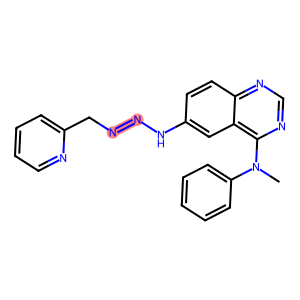

In [ ]:
from rdkit.Chem.Draw import IPythonConsole # для настройки визуализации

# Настройка изображений
IPythonConsole.ipython_useSVG = True # векторная графика
IPythonConsole.molSize = 300, 300 # размер

azo_A_324 = Chem.MolFromSmarts('[#7;!R]=[#7]') # задаем PAINS в формате SMARTS
compound_230285 = Chem.MolFromSmiles(df_pains.loc[6, 'SMILES']) # получаем mol
compound_230285.GetSubstructMatch(azo_A_324) # функция, которая ищет перрвое совпадение
compound_230285

In [ ]:
# Открываем список PAINS из стороннего файла ('pains.smarts')

def load_smarts_file(filename):
    """
    Функция load_smarts_file создает список кортежей с PAINS (patt (mol), name (описание)) из pains.smarts

    Параметры:
               filename - путь к файлу
    Возвращает:
               patterns - список кортежей
    """
    patterns = []
    with open(filename, 'r') as f: # файл открывается с именем filename в режиме чтения ('r')
        for idx, line in enumerate(f): # каждая строка читается по очереди с номером строки (idx), начиная с 0
            line = line.strip() # удаляются пробельные символы по краям
            if not line or line.startswith('#'):  # пропускаем пустые строки и комментарии
                continue
            parts = line.split() # строка разбивается по пробелам
            if len(parts) >= 2:
                smarts, name = parts[0], ' '.join(parts[1:]) # первый элемент (parts[0]) принимается за SMARTS
            else:
                smarts, name = parts[0], f'pattern_{idx+1}' # остальные элементы объединяются через пробел в одно описание

            patt = Chem.MolFromSmarts(smarts) # преобразуем smarts в mol и записываем в переменную patt
            patterns.append((patt, name)) # добавляем patt, name в список patterns

    return patterns

# Вызов функции patterns:
patterns = load_smarts_file('pains.smarts')
print(f"Загружено {len(patterns)} паттернов.")

Загружено 480 паттернов.


In [ ]:
print(patterns)

[(<rdkit.Chem.rdchem.Mol object at 0x7e00cc616500>, '<regId="ene_six_het_A(483)">'), (<rdkit.Chem.rdchem.Mol object at 0x7e00cc616880>, '<regId="hzone_phenol_A(479)">'), (<rdkit.Chem.rdchem.Mol object at 0x7e00cc6168f0>, '<regId="anil_di_alk_A(478)">'), (<rdkit.Chem.rdchem.Mol object at 0x7e00cc6169d0>, '<regId="indol_3yl_alk(461)">'), (<rdkit.Chem.rdchem.Mol object at 0x7e00cc504040>, '<regId="quinone_A(370)">'), (<rdkit.Chem.rdchem.Mol object at 0x7e00cc616810>, '<regId="azo_A(324)">'), (<rdkit.Chem.rdchem.Mol object at 0x7e00cc5040b0>, '<regId="imine_one_A(321)">'), (<rdkit.Chem.rdchem.Mol object at 0x7e00cc504190>, '<regId="mannich_A(296)">'), (<rdkit.Chem.rdchem.Mol object at 0x7e00cc504200>, '<regId="anil_di_alk_B(251)">'), (<rdkit.Chem.rdchem.Mol object at 0x7e00cc504270>, '<regId="anil_di_alk_C(246)">'), (<rdkit.Chem.rdchem.Mol object at 0x7e00cc504120>, '<regId="ene_rhod_A(235)">'), (<rdkit.Chem.rdchem.Mol object at 0x7e00cc504350>, '<regId="hzone_phenol_B(215)">'), (<rdkit.Ch

In [ ]:
def get_pains_hits(smiles, patterns):
    """
    Функция get_pains_hits для поиска PAINS по каталогу patterns

    Входные параметры:
                       smiles - строка SMILES
                       patterns - переменная с каталогом PAINS
    Возвращает:
               hits - список названий найденных PAINS
    """
    mol = Chem.MolFromSmiles(smiles)
    hits = []
    for patt, name in patterns:
        if mol.HasSubstructMatch(patt):
            hits.append(name)
    return hits

In [ ]:
df['PAINS_load'] = df['SMILES'].apply(lambda s: get_pains_hits(s, patterns)) # применение фуункции get_pains_hits

# Задаем булевые переменные has_rdkit, has_load. При наличии PAINS, переменные = True
has_rdkit = df['PAINS_RDKit'].apply(lambda x: len(x) > 0)
has_load = df['PAINS_load'].apply(lambda x: len(x) > 0)

df['has_any_pains'] = has_rdkit | has_load # задаем новый булевой столбец 'has_any_pains', где True - наличие хотябы одного PAINS
df_pains = df[df['has_any_pains']].copy()
print('Кол-во строк с PAINS: ', len(df_pains))
df_pains.head(6)

Кол-во строк с PAINS:  506


,molecule_chembl_id,SMILES,IC50_nM,PAINS_RDKit,PAINS_load,has_any_pains
6,CHEMBL137635,CN(c1ccccc1)c1ncnc2ccc(N/N=N/Cc3ccccn3)cc12,9300.0,[azo_A(324)],"[<regId=""azo_A(324)"">]",True
7,CHEMBL306988,CC(=C(C#N)C#N)c1ccc(NC(=O)CCC(=O)O)cc1,500000.0,[ene_cyano_A(19)],"[<regId=""ene_cyano_A(19)"">]",True
9,CHEMBL77085,N#CC(C#N)=Cc1cc(O)ccc1[N+](=O)[O-],96000.0,[ene_cyano_A(19)],"[<regId=""ene_cyano_A(19)"">]",True
13,CHEMBL77724,COc1cc(C=C(C#N)C#N)cc(OC)c1,1250000.0,[ene_cyano_A(19)],"[<regId=""ene_cyano_A(19)"">]",True
14,CHEMBL420385,N#CC(C#N)=Cc1ccc(N2CCOCC2)cc1,625000.0,"[anil_di_alk_B(251), ene_cyano_A(19)]","[<regId=""anil_di_alk_B(251)"">, <regId=""ene_cya...",True
15,CHEMBL76904,N#CC(C#N)=Cc1ccc(O)c(O)c1,35000.0,"[catechol_A(92), ene_cyano_A(19)]","[<regId=""ene_cyano_A(19)"">]",True


In [ ]:
df = df[~df['has_any_pains']].drop(columns=['PAINS_RDKit', 'PAINS_load', 'has_any_pains']).copy()

print(f"Кол-во строк после удаления PAINS: {len(df)}")
df.head(6)

Кол-во строк после удаления PAINS: 5588


,molecule_chembl_id,SMILES,IC50_nM
0,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,41.0
3,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,170.0
8,CHEMBL66879,O=C(O)/C=C/c1ccc(O)cc1,3000000.0
10,CHEMBL443268,Cc1cc(C(=O)NCCN2CCOCC2)[nH]c1/C=C1\C(=O)N(C)c2...,5310.0
11,CHEMBL76979,COc1cc(/C=C(\C#N)C(=O)O)cc(OC)c1O,264000.0
12,CHEMBL76589,N#CC(C#N)=C(N)/C(C#N)=C/c1ccc(O)cc1,125.0


#⚡ 5. Анализ биологической активности (ADME)

<img src="https://raw.githubusercontent.com/OlgaOVolkova/Biochemistry_26-27_Practice/main/images/ADME.png" width="250">  

## 📌 **«Что происходит с лекарством в нашем организме?» ADME?**
*   Absorption - передачи лекарственного препарата от места введения к месту действия
*   Distribution - распределение лекарственного средства между тканями
*   Metabolism - расщепление (только часть препарата достигнет цели)
*   Excretion - соединения и их метаболиты должны выводиться из организма. Неполное выведение может привести к их накоплению и возможным негативным последствиям.

## 📌 Правило пяти Липински (RO5)
— это эмпирическое правило для оценки сходства с лекарством или определения того, обладает ли химическое соединение с определенной фармакологической или биологической активностью, химическими свойствами и физическими свойствами, которые могут сделать его перорально активным препаратом для человека.

**Правило RO5:** *в общем случае перорально активный препарат должен нарушать не более одного из следующих условий:*
* *Молекулярная масса (MW) <= 500 Да*
* *Количество акцепторов водородных связей (HBA) <= 10*
* *Количество доноров водородных связей (HBD) <= 5*
* *LogP (коэффициент распределения) <= 5*

**Правило не предсказывает, является ли соединение фармакологически активным.**

In [ ]:
# Импорт модулей для расчета дескрипторов
from rdkit.Chem import Descriptors

from rdkit.Chem.Descriptors import TPSA
from rdkit.Chem import Lipinski

Расчет дескрипторов:
*   Молекулярной массы (WM) - влияет на растворимость и биодоступность
*   Коэффициента распределения октанол/вода (LogP) - гидрофобность (растворимость, проницаемость через мембраны, накопление в жировых тканях)
*   Колличества доноров/акцепторов вводородной связи (HBD/HBA) - количество связей с белком - мишенью (аффинность), проницаемость через мембраны

In [ ]:
df['MW'] = df.SMILES.apply(lambda x: Descriptors.MolWt(Chem.MolFromSmiles(x)))
df['LogP'] = df.SMILES.apply(lambda x: Descriptors.MolLogP(Chem.MolFromSmiles(x)))
df['HBD'] = df.SMILES.apply(lambda x: Descriptors.NumHDonors(Chem.MolFromSmiles(x)))
df['HBA'] = df.SMILES.apply(lambda x: Descriptors.NumHAcceptors(Chem.MolFromSmiles(x)))

# Вывод df с рассчитанными дескрипторами
df.head(5)

,molecule_chembl_id,SMILES,IC50_nM,MW,LogP,HBD,HBA
0,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,41.0,383.814,4.45034,3,4
3,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,170.0,482.903,3.61432,3,6
8,CHEMBL66879,O=C(O)/C=C/c1ccc(O)cc1,3000000.0,164.160,1.49000,2,2
10,CHEMBL443268,Cc1cc(C(=O)NCCN2CCOCC2)[nH]c1/C=C1\C(=O)N(C)c2...,5310.0,539.999,3.22822,3,7
11,CHEMBL76979,COc1cc(/C=C(\C#N)C(=O)O)cc(OC)c1O,264000.0,249.222,1.40098,2,5


In [ ]:
# Расчет штрафных баллов (penalty) за несоответствие правилу пяти Лепински

def penalty_RO5(row):  # Функция для расчета penalty
    penalty = 0
    if row['MW'] > 500:
        penalty += 1
    if row['LogP'] > 5:
        penalty += 1
    if row['HBD'] > 5:
        penalty += 1
    if row['HBA'] > 10:
        penalty += 1
    return penalty

In [ ]:
# Применение функции penalty_RO5 к df с созданием столба 'penalty':
df['penalty_RO5'] = df.apply(penalty_RO5, axis=1)

print(f"Количество соединений с penalty > 1: {(df['penalty_RO5'] > 1).sum()}")
df = df.sort_values('penalty_RO5', ascending=False) # сотировка строк по столбцу 'penalty' по убыванию
df.head()

Количество соединений с penalty > 1: 926


,molecule_chembl_id,SMILES,IC50_nM,MW,LogP,HBD,HBA,penalty_RO5
5963,CHEMBL2333163,O=C(NCCc1ccc(O)c(Br)c1)/C(Cc1cc(Br)c(O)c(Oc2cc...,600.0,1412.367,10.4437,11,15,4
4038,CHEMBL474561,O=C1c2c(c3c4ccc(O)cc4n(O[C@@H]4O[C@H](CO)[C@@H...,200000.0,671.619,0.2568,9,13,3
1903,CHEMBL282655,O=C1c2c(c3c4cccc(O)c4n(C4OC(CO)C(O)C(O)C4O)c3c...,200000.0,640.605,1.8190,9,11,3
1901,CHEMBL277408,CS(=O)(=O)NN1C(=O)c2c(c3c4cccc(O)c4n(C4OC(CO)C...,200000.0,612.573,-0.1272,8,11,3
5964,CHEMBL505637,O=C(NCCc1ccc(O)c(Br)c1)/C(Cc1cc(Br)c(O)c(-c2cc...,1300.0,942.250,6.6892,8,10,3


## Правила Ghose и Veber

📌**Молекулярная рефракция (MR, molar refractivity)** — это физико-химический параметр, который отражает размер молекулы и её поляризуемость. Определяет размер и дисперсионные силы (взаимодействие с белками).

📌**Количество атомов (Atom_Number)** определяет размер.

📌 **Правило Arup K. Ghose:**
*Вероятность пропуска полезных соединений составляет менее 20% в следующих диапазонах:*

* *LogP ∈ [−0.4, 5.6]*
* *MR ∈ [40, 130]*
* *MW ∈ [160, 480]*
* *Atom_Number ∈ [20, 70]*
---
Ghose, A. K., Viswanadhan, V. N. & Wendoloski, J. J. A Knowledge-Based Approach in Designing Combinatorial or Medicinal Chemistry Libraries for Drug Discovery. 1. A Qualitative and Quantitative Characterization of Known Drug Databases. J. Comb. Chem. 1, 55–68 (1998).(https://doi.org/10.1021/cc9800071)







In [ ]:
# Рассчет и добавление MR и Atom_Number для проверки правила Гоуза

mr_values = df.SMILES.apply(lambda x: Descriptors.MolMR(Chem.MolFromSmiles(x)))
atom_number_values = df.SMILES.apply(lambda x: Chem.rdchem.Mol.GetNumAtoms(Chem.MolFromSmiles(x)))

df['MR'] = mr_values
df['Atom_Number'] = atom_number_values

df.head(5)

,molecule_chembl_id,SMILES,IC50_nM,MW,LogP,HBD,HBA,penalty_RO5,MR,Atom_Number
5963,CHEMBL2333163,O=C(NCCc1ccc(O)c(Br)c1)/C(Cc1cc(Br)c(O)c(Oc2cc...,600.0,1412.367,10.4437,11,15,4,301.1616,75
4038,CHEMBL474561,O=C1c2c(c3c4ccc(O)cc4n(O[C@@H]4O[C@H](CO)[C@@H...,200000.0,671.619,0.2568,9,13,3,169.9830,49
1903,CHEMBL282655,O=C1c2c(c3c4cccc(O)c4n(C4OC(CO)C(O)C(O)C4O)c3c...,200000.0,640.605,1.8190,9,11,3,166.5990,47
1901,CHEMBL277408,CS(=O)(=O)NN1C(=O)c2c(c3c4cccc(O)c4n(C4OC(CO)C...,200000.0,612.573,-0.1272,8,11,3,149.6320,43
5964,CHEMBL505637,O=C(NCCc1ccc(O)c(Br)c1)/C(Cc1cc(Br)c(O)c(-c2cc...,1300.0,942.250,6.6892,8,10,3,201.4996,50


In [ ]:
# Рассчет penalty для проверки правила Гоуза

def penalty_Ghose(row):
    penalty = 0
    if row['LogP'] < -0.4 or row['LogP'] > 5.6:
        penalty += 1
    if row['MR'] < 40 or row['MR'] > 130:
        penalty += 1
    if row['MW'] < 160 or row['MW'] > 480:
        penalty += 1
    if row['Atom_Number'] < 20 or row['Atom_Number'] > 70:
        penalty += 1
    return penalty

In [ ]:
# Применение функции penalty_Ghose к df с созданием столба 'penalty_Ghose':
df['penalty_Ghose'] = df.apply(penalty_Ghose, axis=1)

print(f"Количество соединений с penalty > 0: {(df['penalty_Ghose'] != 0).sum()}")
df = df.sort_values('penalty_Ghose', ascending=False) # сотировка строк по столбцу 'penalty' по убыванию
df.head()

Количество соединений с penalty > 0: 2512


,molecule_chembl_id,SMILES,IC50_nM,MW,LogP,HBD,HBA,penalty_RO5,MR,Atom_Number,penalty_Ghose
7967,CHEMBL3739527,C#Cc1cccc(Nc2ncnc3cc(OCCOC(=O)CC4=C(C)/C(=C/c5...,27.0,1042.195,11.78770,1,11,3,290.6185,75,4
5963,CHEMBL2333163,O=C(NCCc1ccc(O)c(Br)c1)/C(Cc1cc(Br)c(O)c(Oc2cc...,600.0,1412.367,10.44370,11,15,4,301.1616,75,4
7220,CHEMBL3400291,Cc1c(Cc2cccc(N(C)S(=O)(=O)CCCNCCCCCC(=O)N3CCN(...,10000.0,1000.143,5.70562,1,15,3,265.5615,71,4
5150,CHEMBL1200558,CC[C@H](C)[C@H](N)C1=N[C@H](C(=O)N[C@@H](CC(C)...,5377.0,1422.720,-1.67760,17,19,3,369.3042,100,4
7965,CHEMBL3739771,C#Cc1cccc(Nc2ncnc3cc(OCCOC(=O)Cc4c(C)n(C(=O)c5...,33.0,1044.945,10.91134,1,13,3,286.3287,75,4


📌 **Количество вращающихся связей (Rotatable bonds, RB).** Вращающаяся связь — это химическая связь в молекуле, вокруг которой возможно вращение фрагментов молекулы относительно друг друга без разрыва самой связи. Определяет гибкость молекулы.

📌 **Tопологическая полярная площадь поверхности (Topological Polar Surface Area, TPSA)**  — это параметр, который показывает, какая часть поверхности молекулы является полярной или способна участвовать в образовании водородных связей. Определяет полярность, водородные связи.


📌 **Правило Daniel F. Veber:**

* *RB <= 10*
* *TPSA <= 140*
* *H_bond <= 12*

---
Veber, D. F. et al. Molecular Properties That Influence the Oral Bioavailability of Drug Candidates. J. Med. Chem. 45, 2615–2623 (2002).(https://doi.org/10.1021/jm020017n)

In [ ]:
# Рассчет и добавление MR и Atom_Number для проверки правила Вебера

RB_values = df.SMILES.apply(lambda x: Lipinski.NumRotatableBonds(Chem.MolFromSmiles(x)))
TPSA_values = df.SMILES.apply(lambda x: Descriptors.TPSA(Chem.MolFromSmiles(x)))

df['RB'] = RB_values
df['TPSA'] = TPSA_values
df['H_bond'] = df['HBD'] + df['HBA']

df.head(5)


,molecule_chembl_id,SMILES,IC50_nM,MW,LogP,HBD,HBA,penalty_RO5,MR,Atom_Number,penalty_Ghose,RB,TPSA,H_bond
7967,CHEMBL3739527,C#Cc1cccc(Nc2ncnc3cc(OCCOC(=O)CC4=C(C)/C(=C/c5...,27.0,1042.195,11.78770,1,11,3,290.6185,75,4,18,154.99,12
5963,CHEMBL2333163,O=C(NCCc1ccc(O)c(Br)c1)/C(Cc1cc(Br)c(O)c(Oc2cc...,600.0,1412.367,10.44370,11,15,4,301.1616,75,4,21,295.45,26
7220,CHEMBL3400291,Cc1c(Cc2cccc(N(C)S(=O)(=O)CCCNCCCCCC(=O)N3CCN(...,10000.0,1000.143,5.70562,1,15,3,265.5615,71,4,19,201.67,16
5150,CHEMBL1200558,CC[C@H](C)[C@H](N)C1=N[C@H](C(=O)N[C@@H](CC(C)...,5377.0,1422.720,-1.67760,17,19,3,369.3042,100,4,31,530.87,36
7965,CHEMBL3739771,C#Cc1cccc(Nc2ncnc3cc(OCCOC(=O)Cc4c(C)n(C(=O)c5...,33.0,1044.945,10.91134,1,13,3,286.3287,75,4,18,171.33,14


In [ ]:
# Рассчет penalty для проверки правила Вебера

def penalty_Veber(row):
    penalty = 0
    if row['RB'] > 10:
        penalty += 1
    if row['TPSA'] > 140:
        penalty += 1
    if row['H_bond'] > 12:
        penalty += 1
    return penalty

In [ ]:
# Применение функции penalty_Veber к df с созданием столба 'penalty_Veber':
df['penalty_Veber'] = df.apply(penalty_Veber, axis=1)

print(f"Количество соединений с penalty > 0: {(df['penalty_Veber'] > 0).sum()}")
df.head(2)

Количество соединений с penalty > 0: 561


,molecule_chembl_id,SMILES,IC50_nM,MW,LogP,HBD,HBA,penalty_RO5,MR,Atom_Number,penalty_Ghose,RB,TPSA,H_bond,penalty_Veber
7967,CHEMBL3739527,C#Cc1cccc(Nc2ncnc3cc(OCCOC(=O)CC4=C(C)/C(=C/c5...,27.0,1042.195,11.7877,1,11,3,290.6185,75,4,18,154.99,12,2
5963,CHEMBL2333163,O=C(NCCc1ccc(O)c(Br)c1)/C(Cc1cc(Br)c(O)c(Oc2cc...,600.0,1412.367,10.4437,11,15,4,301.1616,75,4,21,295.45,26,3


In [ ]:
mask = (df['penalty_RO5'] > 1) & (df['penalty_Ghose'] != 0) & (df['penalty_Veber'] != 0) # Поиск строк с penalty
penalty_df = df[mask].copy() # новый датафрейм с penalty
penalty_df = penalty_df.sort_values('penalty_RO5', ascending=False)
print('Кол-во соединенй, несоответствующие правилам Липински, Гоуза и Вебера: ', len(penalty_df))
penalty_df.head()

Кол-во соединенй, несоответствующие правилам Липински, Гоуза и Вебера:  361


,molecule_chembl_id,SMILES,IC50_nM,MW,LogP,HBD,HBA,penalty_RO5,MR,Atom_Number,penalty_Ghose,RB,TPSA,H_bond,penalty_Veber
5963,CHEMBL2333163,O=C(NCCc1ccc(O)c(Br)c1)/C(Cc1cc(Br)c(O)c(Oc2cc...,600.0,1412.367,10.44370,11,15,4,301.1616,75,4,21,295.45,26,3
1884,CHEMBL278526,N#CCC(=O)NN1C(=O)c2c(c3c4cccc(O)c4n(C4OC(CO)C(...,200000.0,601.528,0.35348,8,11,3,150.0252,44,2,4,241.60,19,2
7967,CHEMBL3739527,C#Cc1cccc(Nc2ncnc3cc(OCCOC(=O)CC4=C(C)/C(=C/c5...,27.0,1042.195,11.78770,1,11,3,290.6185,75,4,18,154.99,12,2
7220,CHEMBL3400291,Cc1c(Cc2cccc(N(C)S(=O)(=O)CCCNCCCCCC(=O)N3CCN(...,10000.0,1000.143,5.70562,1,15,3,265.5615,71,4,19,201.67,16,3
5150,CHEMBL1200558,CC[C@H](C)[C@H](N)C1=N[C@H](C(=O)N[C@@H](CC(C)...,5377.0,1422.720,-1.67760,17,19,3,369.3042,100,4,31,530.87,36,3


In [ ]:
# Формирование исходного датасета df_final
df_final = df.loc[~mask, ['molecule_chembl_id', 'SMILES']].copy() # новый датафрейм с соединениями, удовлетворяющими правилам Липинского, Гоуза и Вебера
df_final = df_final.sort_values('molecule_chembl_id', ascending=True)
print('Кол-во строк в финальном очищенном датасете: ', len(df_final))
df_final.head()

Кол-во строк в финальном очищенном датасете:  5227


,molecule_chembl_id,SMILES
923,CHEMBL10,C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...
799,CHEMBL100714,COc1ccc(Nc2ncnc3cc(OC)c(OC)cc23)cc1OC
2167,CHEMBL101253,Clc1ccc(Nc2nnc(Cc3ccncc3)c3ccccc23)cc1
835,CHEMBL101581,COc1cc2nccc(Oc3cccc(Br)c3)c2cc1OC
5153,CHEMBL1016,CCOc1nc2cccc(C(=O)O)c2n1Cc1ccc(-c2ccccc2-c2nnn...


In [ ]:
df_final.to_csv('practice_2_result.csv', index=False)

# ⚡ Задание

1. В исходном датасете (https://github.com/OlgaOVolkova/Biochemistry_26-27_Practice/blob/main/data/practice_2_task.csv) найти и удалить пропуски данных. (1 б)
2. Провести обработку SMILES комплексов, привести все SMILES к каноническому виду. (1 б)
3. Удалить дупликаты записей. (1 б)
4. Найти и удалить PAINS. (2 б)
5. Определить соединения, не соответствующие правилам Lipinski, Ghose и Veber, и удалить их из датасета. Полученный датасет сохранить в файл "practice_2_result" в формате csv. (3 б)